In [ ]:
!pip install datasets
!pip install sentence_transformers
!pip install umap
!pip install bertopic
!pip install hdbscan

  Preparing metadata (setup.py) ... done
  Created wheel for umap: filename=umap-0.1.1-py3-none-any.whl size=3541 sha256=38bd569ccee5338f8b78a272c8e8119c68d845654f7601df627593a86cfea434
  Stored in directory: /root/.cache/pip/wheels/48/4a/1c/1d511cbb0413a448d8546e958f8e82b98d9bb493038d19ece2
Successfully built umap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.0/153.0 kB 6.8 MB/s eta 0:00:00


In [ ]:
import nltk
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from umap.umap_ import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from google.colab import files
from wordcloud import WordCloud
from nltk.corpus import stopwords
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

## Funzione di preprocess per standardizzare gli abstract

In [ ]:
stop_words = set(stopwords.words('italian'))
punctuation = set(string.punctuation)

def preprocess_text(text):
    tokens = text.lower().split()
    tokens = [token.strip(string.punctuation) for token in tokens]
    filtered_tokens = [word for word in tokens if word not in stop_words and word not in punctuation]
    return ' '.join(filtered_tokens)

## Lettura del detaset


In [ ]:
uploaded = files.upload()
df = pd.read_excel(list(uploaded.keys())[0])

df = df[["abstract"]]
df["abstract"] = df["abstract"].fillna("").astype(str)

abstract_list = []
preprocessed_abstracts = []
for i, row in df.iterrows():
    abstract = row["abstract"]
    abstract_list.append(abstract)
    preprocessed_abstracts.append(preprocess_text(abstract))

# abstract_list = [str(text[0]) for text in abstract]
# abstract_list_clean = [preprocess(abstract) for abstract in abstract_list]

Saving testi_tradotti.xlsx to testi_tradotti.xlsx


## Embedding degli abstract

In [ ]:
sentence_model = SentenceTransformer("thenlper/gte-small")
embeddings = sentence_model.encode(abstract_list, show_progress_bar=True)
embeddings.shape

modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/66.7M [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/93 [00:00<?, ?it/s]

(2968, 384)

## Creazione modello UMAP e riduzione della dimensionalità

In [ ]:
# n_components = 5, cluster a 5 dimensioni -> da errore dopo in "df = pd.dataframe(....)"
# o si imposta n_components a 2 o si usa "reduced_embeddings[:, :2]" in modo che dataframe usi solo le prime 2 dimensioni, non so qual è la soluzione migliore
umap_model = UMAP(n_components=5, min_dist=0.0, metric="cosine", random_state=42)
reduced_embeddings = umap_model.fit_transform(embeddings)

## Clustering degli embeddings

In [ ]:
hdbscan_model = HDBSCAN(min_cluster_size=50, metric="euclidean",
cluster_selection_method="eom").fit(reduced_embeddings)
clusters = hdbscan_model.labels_

## Creazione modello BERTopic

In [ ]:
bert_model = BERTopic(
    embedding_model=sentence_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    verbose=True
)

topics, probs = bert_model.fit_transform(preprocessed_abstracts, embeddings)

2025-11-20 11:23:49,295 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-11-20 11:24:06,113 - BERTopic - Dimensionality - Completed ✓
2025-11-20 11:24:06,115 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-11-20 11:24:06,202 - BERTopic - Cluster - Completed ✓
2025-11-20 11:24:06,207 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-11-20 11:24:06,505 - BERTopic - Representation - Completed ✓


In [ ]:
topic_labels = bert_model.generate_topic_labels(nr_words=3, separator=' ')
fig = bert_model.visualize_documents(
    preprocessed_abstracts,
    reduced_embeddings=reduced_embeddings,
    width=1200,
    hide_annotations=True
)

# num_topics = len([t for t in bert_model.get_topics().keys() if t != -1])
# print(num_topics)

fig.update_layout(font=dict(size=16))
bert_model.visualize_heatmap(n_clusters = 7)

 ## Grafico a barre dei main topics

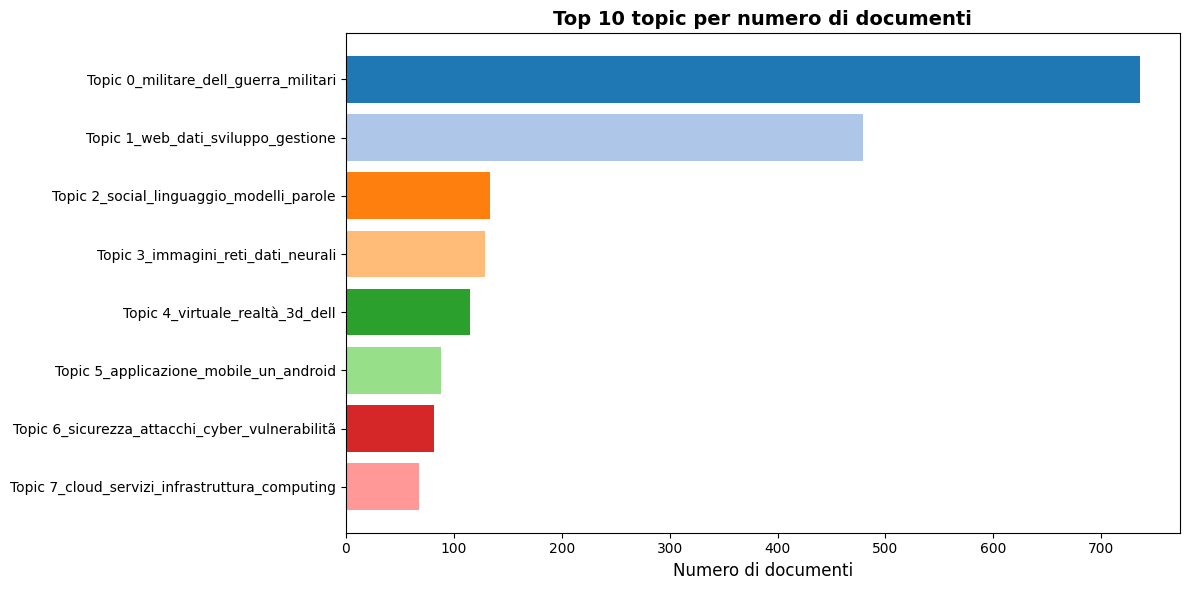

In [ ]:
topic_info = bert_model.get_topic_info()
# Rimuovi il topic outlier (-1) se presente
topic_info_filtered = topic_info[topic_info['Topic'] != -1].head(10)

plt.figure(figsize=(12, 6))
plt.barh(range(len(topic_info_filtered)),
         topic_info_filtered['Count'],
         color=plt.cm.tab20(range(len(topic_info_filtered))))
plt.yticks(range(len(topic_info_filtered)),
           [f"Topic {row['Name']}" for _, row in topic_info_filtered.iterrows()])
plt.xlabel('Numero di documenti', fontsize=12)
plt.title('Top 10 topic per numero di documenti', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('main_topics.png', dpi=300, bbox_inches='tight')
plt.show()

## Scatter plot

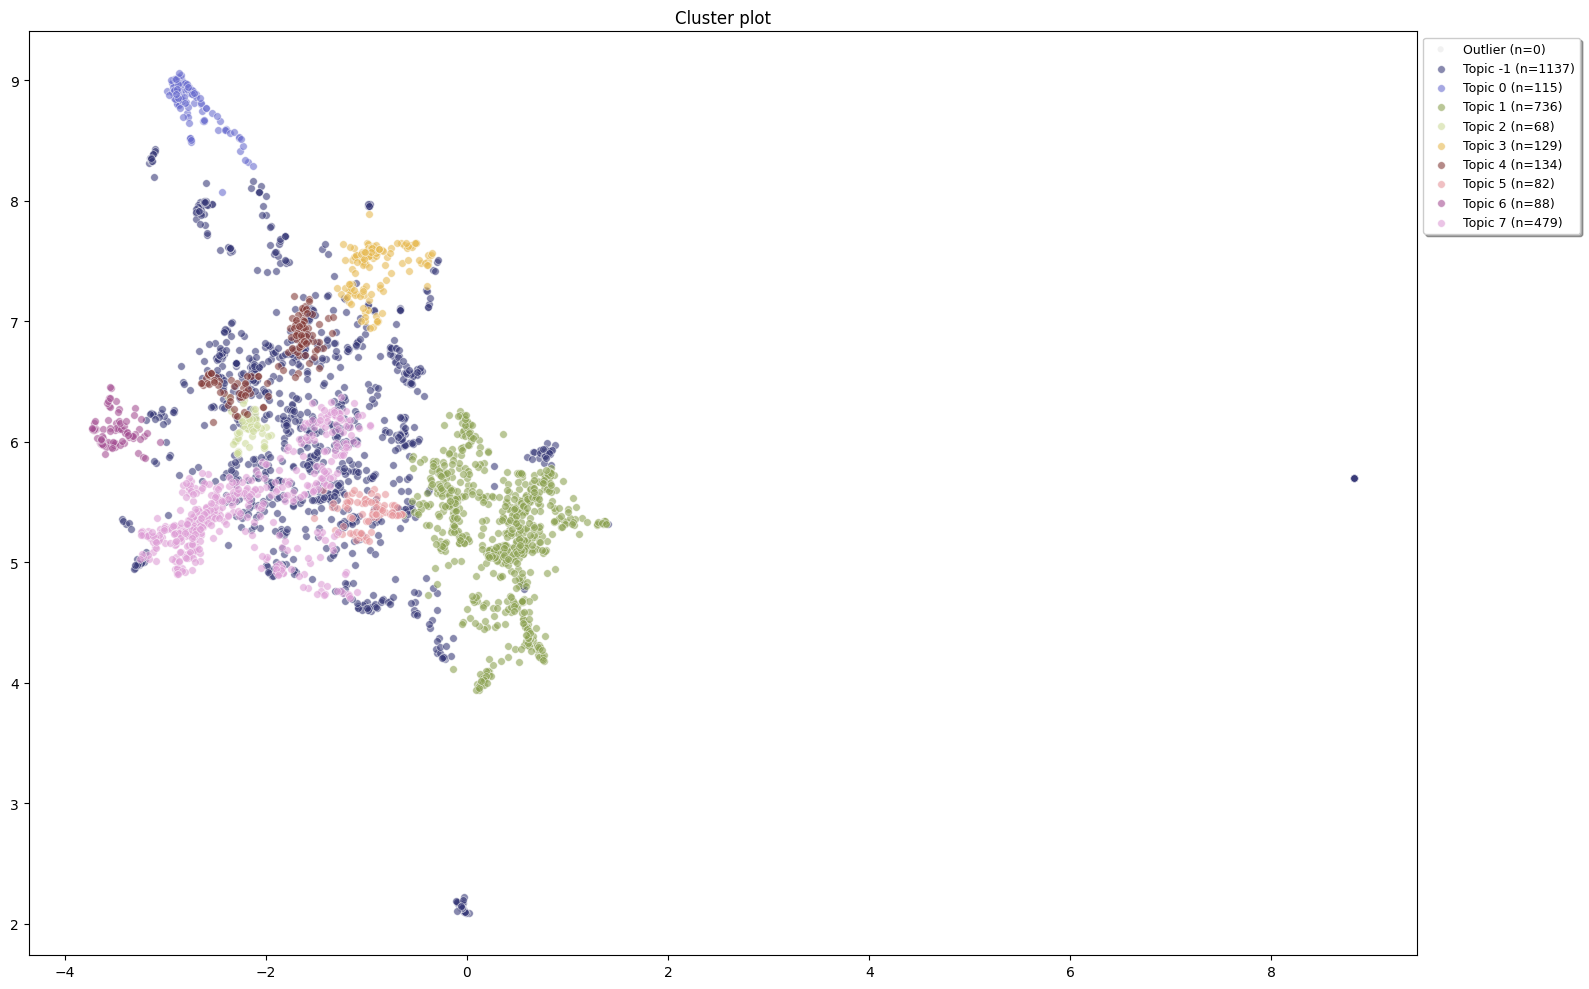

In [ ]:
df = pd.DataFrame(reduced_embeddings[:, :2], columns=["x", "y"])
df["cluster"] = [str(c) for c in clusters]

# Separa outlier e cluster validi
to_plot_df = df.loc[df.cluster != -1, :]
outliers_df = df.loc[df.cluster == -1, :]

fig, ax = plt.subplots(figsize=(16, 10))

ax.scatter(outliers_df.x,
           outliers_df.y,
           alpha=0.3,
           s=20,
           c="lightgrey",
           label=f"Outlier (n={len(outliers_df)})", edgecolors='none')

unique_clusters = sorted(to_plot_df.cluster.unique())
colors = plt.cm.tab20b(np.linspace(0, 1, len(unique_clusters)))

# Plot di ogni cluster con etichetta
for idx, cluster in enumerate(unique_clusters):
    cluster_data = to_plot_df[to_plot_df.cluster == cluster]
    topic_name = topic_info[topic_info['Topic'] == cluster]['Name'].values
    topic_name = topic_name[0] if len(topic_name) > 0 else f"Topic {cluster}"

    ax.scatter(cluster_data.x, cluster_data.y,
               c=[colors[idx]], alpha=0.6, s=30,
               label=f"{topic_name} (n={len(cluster_data)})",
               edgecolors='white', linewidths=0.5)

ax.set_title('Cluster plot')

ax.legend(bbox_to_anchor=(1, 1),
          loc='upper left',
          fontsize=9,
          frameon=True,
          fancybox=True,
          shadow=True)

plt.tight_layout()
plt.savefig('cluster_plot.png', dpi=300, bbox_inches='tight')
plt.show()


## PIE CHART

   Topic  Count                                      Name  \
1      0    736           0_militare_dell_guerra_militari   
2      1    479              1_web_dati_sviluppo_gestione   
3      2    134        2_social_linguaggio_modelli_parole   
4      3    129              3_immagini_reti_dati_neurali   
5      4    115                 4_virtuale_realtà_3d_dell   
6      5     88          5_applicazione_mobile_un_android   
7      6     82  6_sicurezza_attacchi_cyber_vulnerabilitã   
8      7     68  7_cloud_servizi_infrastruttura_computing   

                                      Representation  \
1  [militare, dell, guerra, militari, all, capito...   
2  [web, dati, sviluppo, gestione, dell, progetto...   
3  [social, linguaggio, modelli, parole, stato, d...   
4  [immagini, reti, dati, neurali, dell, artifici...   
5  [virtuale, realtà, 3d, dell, ambiente, svilupp...   
6  [applicazione, mobile, un, android, sviluppo, ...   
7  [sicurezza, attacchi, cyber, vulnerabilitã, si...   
8 

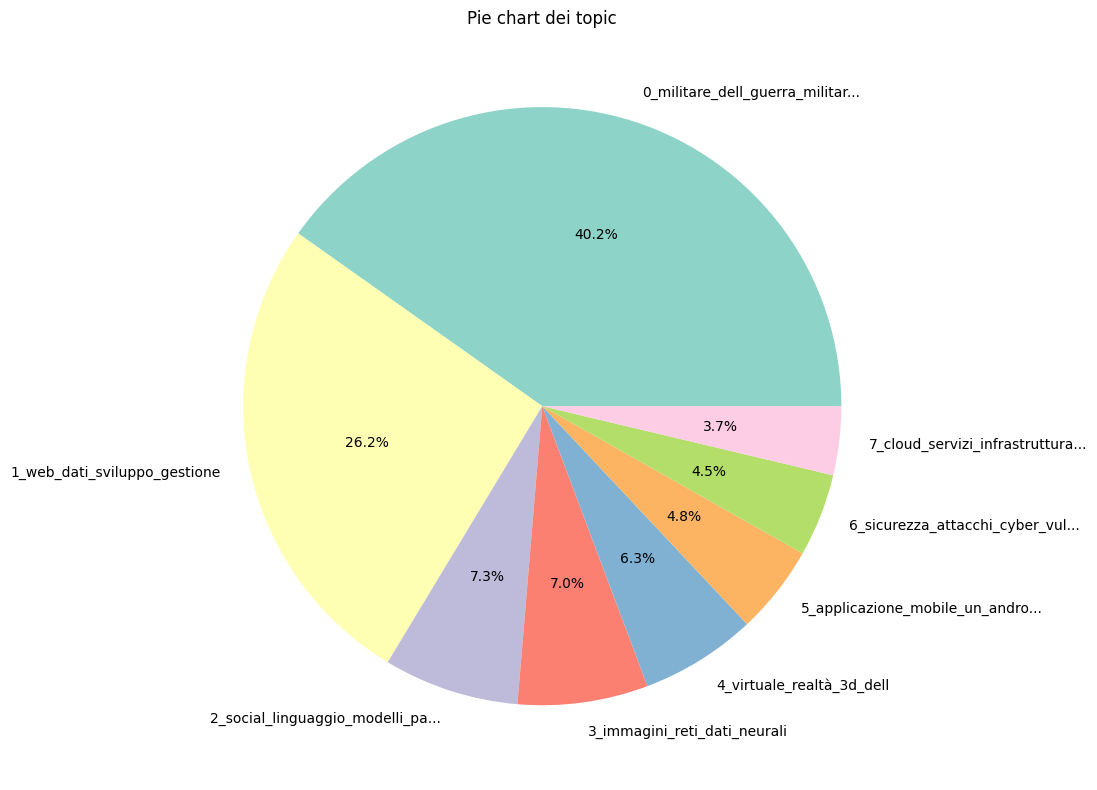

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

# top_n = 10
# topic_counts = topic_info_filtered.head(top_n)
# print(topic_counts)
other_count = topic_info[topic_info['Topic'] != -1]['Count'].sum() - topic_counts['Count'].sum()

sizes = list(topic_counts['Count'])
labels = [f"{row['Name'][:30]}..." if len(row['Name']) > 30 else row['Name']
          for _, row in topic_counts.iterrows()]

colors_pie = plt.cm.Set3(range(len(sizes)))

wedges, texts, autotexts = ax.pie(sizes,
                                  labels=labels,
                                  autopct='%1.1f%%',
                                  colors=colors_pie)

ax.set_title('Pie chart dei topic')

plt.tight_layout()
plt.savefig('topic_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
